# Import

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, t

# Visualization 1 — p-value illustrated

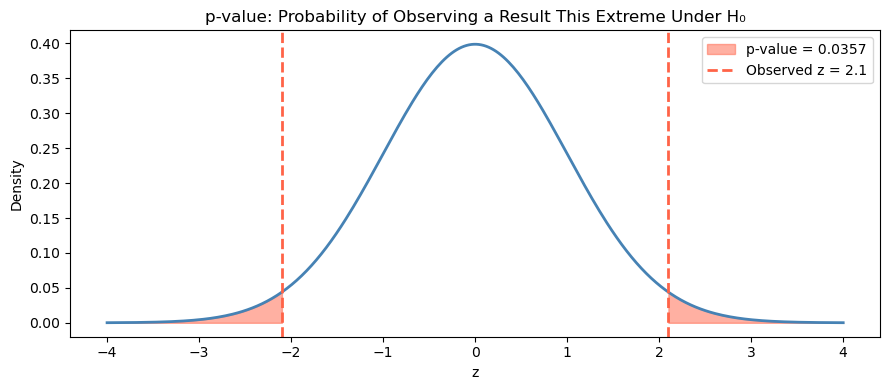

p-value = 0.0357
Reject H0 at alpha=0.05: True


In [5]:
# One-sample z-test scenario
# H0: mu = 0, observe a sample mean that gives z = 2.1

z_observed = 2.1
alpha = 0.05

x = np.linspace(-4, 4, 300)
pdf = norm.pdf(x)
p_value = 2 * (1 - norm.cdf(abs(z_observed)))  # two-tailed

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(x, pdf, color='steelblue', lw=2)

# Shade p-value regions (two-tailed)
ax.fill_between(x, pdf, where=(x >= z_observed), color='tomato', alpha=0.5, label=f'p-value = {p_value:.4f}')
ax.fill_between(x, pdf, where=(x <= -z_observed), color='tomato', alpha=0.5)

# Mark observed z
ax.axvline(z_observed,  color='tomato', lw=2, ls='--', label=f'Observed z = {z_observed}')
ax.axvline(-z_observed, color='tomato', lw=2, ls='--')

ax.set_xlabel('z')
ax.set_ylabel('Density')
ax.set_title('p-value: Probability of Observing a Result This Extreme Under H₀')
ax.legend()
plt.tight_layout()
plt.savefig('pvalue_illustrated.png', dpi=150)
plt.show()

print(f'p-value = {p_value:.4f}')
print(f'Reject H0 at alpha=0.05: {p_value < alpha}')


## p-value Illustrated

The shaded regions show the p-value of 0.0357 — the total probability of observing a z-statistic as extreme as ±2.1 under H₀. Since p=0.0357 < α=0.05, we reject H₀. The key insight this plot conveys is what a p-value actually measures: not the probability that H₀ is true, but the probability of seeing data this extreme assuming H₀ is true. The two symmetric tails reflect the two-tailed nature of the test.

阴影区域显示p值为0.0357——在H₀下观测到z统计量极端到±2.1的总概率。由于p=0.0357 < α=0.05，我们拒绝H₀。这张图传达的核心洞察是p值实际上度量的是什么：不是H₀为真的概率，而是假设H₀为真时看到这么极端数据的概率。两个对称的尾部反映了双尾检验的性质。

# Visualization 2 — Rejection region and significance level

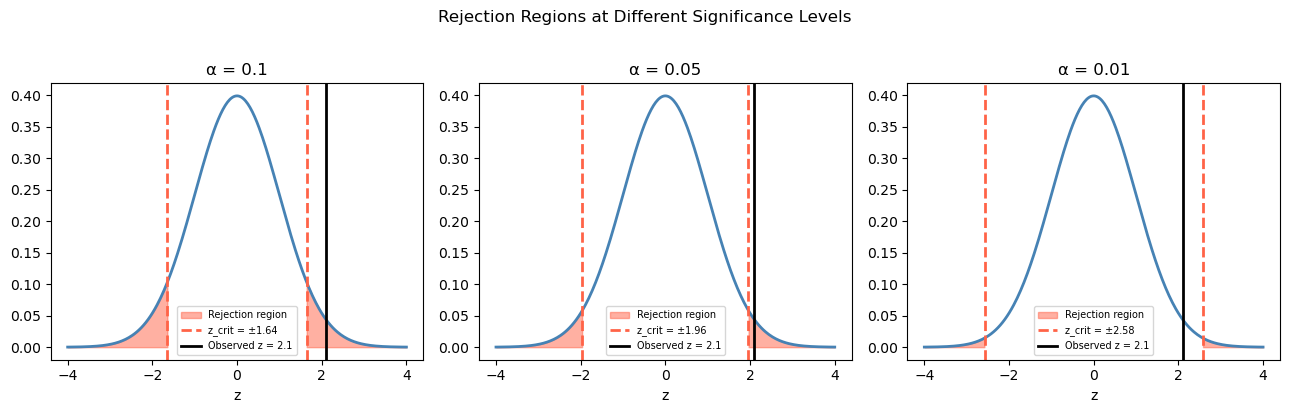

In [8]:
alpha_values = [0.10, 0.05, 0.01]
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, a in zip(axes, alpha_values):
    z_crit = norm.ppf(1 - a / 2)
    ax.plot(x, pdf, color='steelblue', lw=2)

    # Rejection regions
    ax.fill_between(x, pdf, where=(x >= z_crit),  color='tomato', alpha=0.5, label=f'Rejection region')
    ax.fill_between(x, pdf, where=(x <= -z_crit), color='tomato', alpha=0.5)

    # Critical values
    ax.axvline( z_crit, color='tomato', lw=2, ls='--', label=f'z_crit = ±{z_crit:.2f}')
    ax.axvline(-z_crit, color='tomato', lw=2, ls='--')

    # Observed z
    ax.axvline(z_observed, color='black', lw=2, label=f'Observed z = {z_observed}')

    ax.set_title(f'α = {a}')
    ax.set_xlabel('z')
    ax.legend(fontsize=7)

fig.suptitle('Rejection Regions at Different Significance Levels', y=1.02)
plt.tight_layout()
plt.savefig('rejection_regions.png', dpi=150, bbox_inches='tight')
plt.show()


## Rejection Regions

At α=0.10 the critical values are ±1.64, and the observed z=2.1 falls clearly inside the rejection region. At α=0.05 the critical values widen to ±1.96, and z=2.1 still just crosses the threshold. At α=0.01 the critical values expand to ±2.58, and z=2.1 now falls outside the rejection region — H₀ would not be rejected. This illustrates a fundamental tension: stricter significance levels reduce false positives but make it harder to detect real effects.

α=0.10时临界值为±1.64，观测到的z=2.1明显落在拒绝域内。α=0.05时临界值扩大到±1.96，z=2.1仍刚好越过阈值。α=0.01时临界值扩展到±2.58，z=2.1现在落在拒绝域外——H₀将不会被拒绝。这揭示了一个根本性的权衡：更严格的显著性水平减少了假阳性，但也使检测真实效应变得更难。

# Visualization 3 — Type I and Type II errors

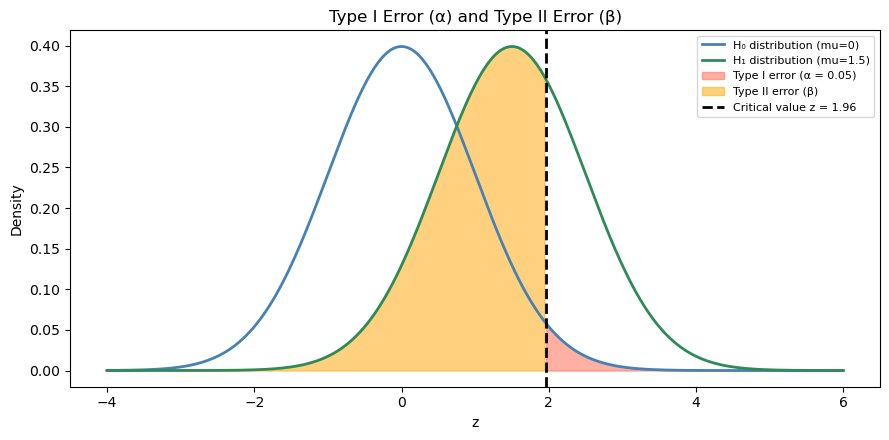

In [14]:
effect_size = 1.5   # distance between H0 and H1 means
alpha = 0.05
z_crit = norm.ppf(1 - alpha / 2)

x = np.linspace(-4, 6, 400)
h0_pdf = norm.pdf(x, 0, 1)
h1_pdf = norm.pdf(x, effect_size, 1)

fig, ax = plt.subplots(figsize=(9, 4.5))

ax.plot(x, h0_pdf, color='steelblue', lw=2, label='H₀ distribution (mu=0)')
ax.plot(x, h1_pdf, color='seagreen',  lw=2, label=f'H₁ distribution (mu={effect_size})')

# Type I error: reject H0 when H0 is true (right tail of H0)
ax.fill_between(x, h0_pdf, where=(x >= z_crit), color='tomato', alpha=0.5, label=f'Type I error (α = {alpha})')

# Type II error: fail to reject H0 when H1 is true (left tail of H1)
ax.fill_between(x, h1_pdf, where=(x <= z_crit), color='orange', alpha=0.5, label='Type II error (β)')

ax.axvline(z_crit, color='black', lw=2, ls='--', label=f'Critical value z = {z_crit:.2f}')

ax.set_xlabel('z')
ax.set_ylabel('Density')
ax.set_title('Type I Error (α) and Type II Error (β)')
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig('type1_type2_errors.png', dpi=150)
plt.show()


## Type I and Type II Errors

The blue curve is the H₀ distribution (mu=0) and the green curve is the H₁ distribution (mu=1.5). The critical value at z=1.96 divides the space. The red region (Type I error, α=0.05) is the probability of rejecting H₀ when it is actually true — a false positive. The orange region (Type II error, β) is the probability of failing to reject H₀ when H₁ is actually true — a false negative. The large orange area shows that with an effect size of only 1.5 and this critical value, the test misses the true effect a substantial fraction of the time. The overlap between the two distributions is the fundamental source of both error types.

蓝色曲线是H₀分布（均值=0），绿色曲线是H₁分布（均值=1.5）。z=1.96处的临界值划分了空间。红色区域（第一类错误，α=0.05）是H₀实际为真时拒绝H₀的概率——假阳性。橙色区域（第二类错误，β）是H₁实际为真时未能拒绝H₀的概率——假阴性。较大的橙色区域表明：在效应量仅为1.5、临界值固定的情况下，检验相当大比例地遗漏了真实效应。两个分布之间的重叠是两类错误的根本来源。

#  Visualization 4 — Statistical power vs. effect size and sample size

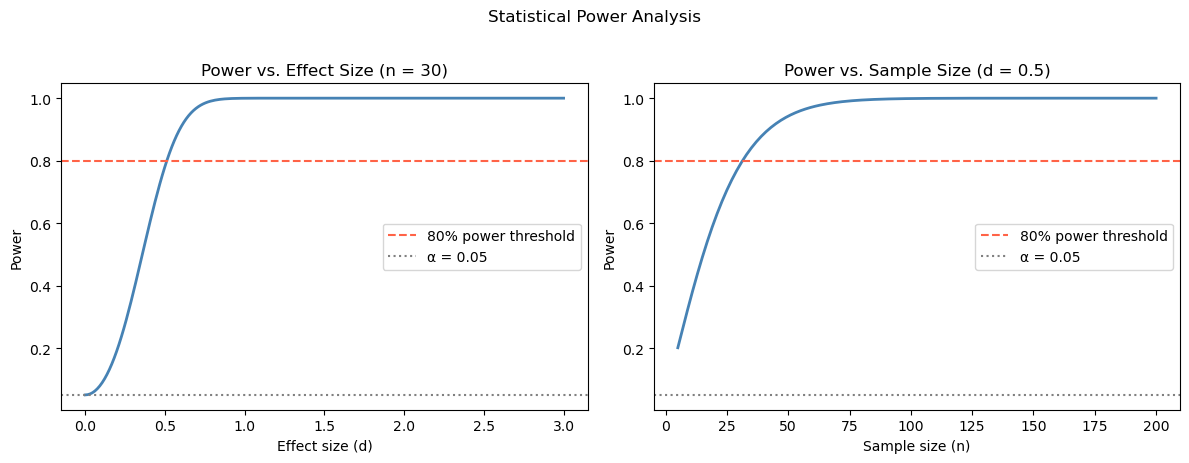

In [17]:
alpha = 0.05
z_crit = norm.ppf(1 - alpha / 2)

# Power vs effect size (fixed n=30)
effect_sizes = np.linspace(0, 3, 200)
n = 30
power_effect = [1 - norm.cdf(z_crit - d * np.sqrt(n)) + norm.cdf(-z_crit - d * np.sqrt(n))
                for d in effect_sizes]

# Power vs sample size (fixed effect size = 0.5)
sample_sizes = np.arange(5, 201)
d = 0.5
power_n = [1 - norm.cdf(z_crit - d * np.sqrt(n)) + norm.cdf(-z_crit - d * np.sqrt(n))
           for n in sample_sizes]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.plot(effect_sizes, power_effect, color='steelblue', lw=2)
ax1.axhline(0.80, color='tomato', lw=1.5, ls='--', label='80% power threshold')
ax1.axhline(alpha, color='gray',   lw=1.5, ls=':',  label=f'α = {alpha}')
ax1.set_xlabel('Effect size (d)')
ax1.set_ylabel('Power')
ax1.set_title(f'Power vs. Effect Size (n = {30})')
ax1.legend()

ax2.plot(sample_sizes, power_n, color='steelblue', lw=2)
ax2.axhline(0.80, color='tomato', lw=1.5, ls='--', label='80% power threshold')
ax2.axhline(alpha, color='gray',   lw=1.5, ls=':',  label=f'α = {alpha}')
ax2.set_xlabel('Sample size (n)')
ax2.set_ylabel('Power')
ax2.set_title(f'Power vs. Sample Size (d = {d})')
ax2.legend()

fig.suptitle('Statistical Power Analysis', y=1.02)
plt.tight_layout()
plt.savefig('power_analysis.png', dpi=150, bbox_inches='tight')
plt.show()


## Power Analysis

The left plot shows that with n=30, power increases rapidly with effect size, crossing the 80% threshold around d=0.5. Beyond d=1.0 power approaches 1.0 — large effects are almost always detected. The right plot shows that with d=0.5, achieving 80% power requires approximately n=50 samples. Below n=25 power drops below 50%, meaning the test fails to detect the effect more often than it succeeds. Both curves illustrate a core principle of study design: small effects and small samples lead to underpowered studies that frequently miss real findings.

左图显示n=30时，功效随效应量迅速增大，在d≈0.5处越过80%阈值。d>1.0后功效趋近1.0——大效应几乎总能被检测到。右图显示d=0.5时，达到80%功效约需n=50个样本。n<25时功效低于50%，意味着检验遗漏真实效应的次数多于检测到的次数。两条曲线都揭示了研究设计的核心原则：小效应加小样本导致功效不足的研究，频繁遗漏真实发现。

# Summary

he four visualizations address four distinct layers of understanding:

1.	The p-value plot illustrates what a p-value actually measures: not the probability that H₀ is true, but the probability of observing a result as extreme as the one obtained, assuming H₀ is true. With z=2.1, the two-tailed p-value is 0.0357, which falls below α=0.05, leading to rejection of H₀;
2.	The rejection region plot shows how the choice of significance level α directly determines the critical values and the size of the rejection region. The same observed z=2.1 leads to rejection at α=0.10 and α=0.05 but not at α=0.01, highlighting that statistical conclusions are sensitive to the threshold chosen;
3.	The Type I and Type II error plot visualizes the fundamental trade-off in hypothesis testing: reducing α (stricter threshold) shrinks the Type I error but enlarges the Type II error, since the two distributions overlap. There is no way to eliminate both error types simultaneously without more data or a larger effect;
4.	The power analysis plot quantifies how power — the probability of correctly rejecting a false H₀ — depends on both effect size and sample size. Achieving the conventional 80% power threshold with a medium effect size (d=0.5) requires roughly 50 samples, and small effects demand substantially more.

Together, the four visualizations build a complete and rigorous picture of hypothesis testing, moving from the definition of a p-value to the practical implications of sample size and effect size on study design.

中文：

本项目可视化了频率派假设检验的核心概念——p值、拒绝域、错误类型与统计功效——这些是应用统计学中使用最广泛但也最常被误解的工具。

四组可视化分别对应四个层次的理解：

1.	p值图展示了p值实际度量的是什么：不是H₀为真的概率，而是假设H₀为真时观测到这么极端结果的概率。z=2.1对应的双尾p值为0.0357，低于α=0.05，因此拒绝H₀；
2.	拒绝域图展示了显著性水平α的选择如何直接决定临界值和拒绝域的大小。相同的z=2.1在α=0.10和α=0.05时导致拒绝，但在α=0.01时不拒绝，说明统计结论对所选阈值敏感；
3.	两类错误图直观呈现了假设检验中的根本权衡：降低α（更严格的阈值）会缩小第一类错误，但由于两个分布存在重叠，第二类错误会扩大。在不增加数据量或效应量的前提下，无法同时消除两类错误；
4.	功效分析图量化了功效——正确拒绝错误H₀的概率——如何同时依赖于效应量和样本量。在中等效应量（d=0.5）下达到常规80%功效阈值约需50个样本，小效应则需要更多。

四组可视化共同构建了对假设检验完整而严谨的理解，从p值的定义到样本量和效应量对研究设计的实际影响，层层递进。